# Speeding up the objective function calculation using numba

The objective function is evaluated over and over again and it makes sense to spent some time to make it faster. Here we use the just-in-time compilation option from `numba`.


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Objective function calculation

### Naive $O(n^2)$ Implementation
Naive implementation with nested loops. This is $O(n^2)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math

In [2]:
def conflicts_naive(board):
    """Calculate the number of conflicts, i.e., the objective function."""
    
    board = np.array(board)
    
    n = len(board)
    val = 0

    # check horizontal (we do not check vertical since the state space is restricted to one queen per col)
    for i in range(n): val += math.comb(np.sum(board == i), 2)
    #print(f"Horizontal value: {val}")
    
    # check for each queen diagonally up and down (only to the right side of the queen)
    for j in range(n):
        q_up = board[j]
        q_down = board[j]
     
        for jj in range(j+1, n):
            q_up -= 1
            q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
        #print(f"Value after queen {j}: {val}")
       
    return(val)    

### $O(n)$ Implementation

A better implementation that should be $O(n)$. Idea: 

1. Count how many queens are in each row (no need to check columns) and how many are in each diagonal.
2. Convert the number of $n$ queens in a row (diagonal) into the numbner of pariwise conflicts in $n$ choose 2. We use a faster special case for the `comb()` function to calcualte the conflicts given the number of queens.   

In [3]:
def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    # we have double the diagonals compared to columns!
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

### Compiled $O(n)$ Implementation
We can use just-in-time compilation for the conflicts function. Code provided by Troy McNitt.

In [4]:
from numba import njit

# with jit (cannot use some Python functions like sum and map)
@njit()
def comb2_jit(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

@njit()
def conflicts_jit(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
 
    cnt = [0] * (5 * n)
 
    for i in range(n):
        cnt[board[i]] += 1
        cnt[(n) + (i + board[i])] += 1
        cnt[(3 * n) + (i - board[i] + n)] += 1
 
    conflicts = 0
    for x in cnt:
        conflicts += comb2_jit(x)
 
    return conflicts

# Compare Timing

Compare runtime on 50 random boards of different sizes.

In [5]:
np.random.seed(1234)
def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

In [6]:
import timeit
 
# run it once to force compilation
conflicts_jit(random_board(4))
    
reps = 20
x = []
naive_times = []
linear_times = []
jit_times = []
 
 
for i in [8] + list(range(50, 500, 50)):
    # do reps replications on random boards
    boards = [random_board(i) for _ in range(reps)]
 
    #print(f"Doing: {i}")

    # number = 1 means we only run it once in timeit 
    naive = timeit.timeit(
        lambda: [conflicts_naive(board) for board in boards], number=1
    )
    linear = timeit.timeit(
        lambda: [conflicts(board) for board in boards], number=1
    )
    jit = timeit.timeit(
        lambda: [conflicts_jit(board) for board in boards], number=1
    )

 
    x.append(i)
    naive_times.append(naive)
    linear_times.append(linear)
    jit_times.append(jit)

# average time per board in microseconds
naive_times = np.array(naive_times) / reps * 1e6
linear_times = np.array(linear_times) / reps * 1e6
jit_times = np.array(jit_times) / reps * 1e6

print("Times for 8x8 board in microseconds")
print(f'naive: {naive_times[0]}, linear: {linear_times[0]}, jit: {jit_times[0]}')
 

Times for 8x8 board in microseconds
naive: 68.15715000811906, linear: 12.311599994063727, jit: 1.0334499961572874


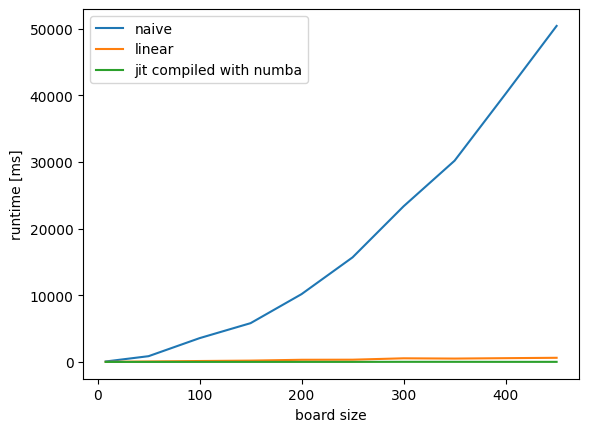

In [7]:
plt.plot(x, naive_times)
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [ms]")
plt.legend(["naive", "linear", "jit compiled with numba"])
plt.show()

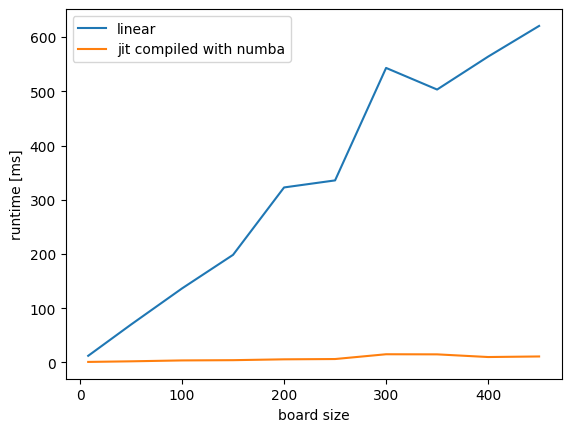

In [8]:
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [ms]")
plt.legend(["linear", "jit compiled with numba"])
plt.show()

> **Lưu ý về các biểu đồ ở trên.** Giá trị trong `naive_times`, `linear_times`, `jit_times` đã được chia cho `reps` và nhân `1e6`, nên đơn vị là **micro giây (µs) cho mỗi bàn cờ**, không phải ms như nhãn trục y của hai biểu đồ gốc. Các ô bên dưới dùng đúng đơn vị µs.

# Bài 6 - Phân tích bổ sung

## 1. Vì sao dùng $C(k,2)$ thì tránh được so sánh từng cặp?

Hàm mục tiêu là số **cặp** quân hậu tấn công nhau. Hai quân hậu tấn công nhau khi chúng nằm trên cùng một *đường* (hàng, đường chéo `i + q[i]`, hoặc đường chéo `i - q[i]`). Nếu một đường chứa $k$ quân hậu thì nó đóng góp đúng $\binom{k}{2} = \frac{k(k-1)}{2}$ cặp xung đột. Vậy:

$$f(\mathbf{q}) = \sum_{\text{hàng}} \binom{k_h}{2} + \sum_{\text{chéo } i+q_i} \binom{k_d}{2} + \sum_{\text{chéo } i-q_i} \binom{k_a}{2}$$

* `conflicts_naive()` so sánh từng quân hậu với mọi quân hậu bên phải: $\binom{n}{2}$ phép so sánh, tức $O(n^2)$.
* `conflicts()` chỉ duyệt $n$ quân hậu **một lần** để tăng bộ đếm của hàng/đường chéo tương ứng ($O(n)$), rồi cộng $\binom{k}{2}$ trên $O(n)$ bộ đếm ($n$ hàng + $2n$ + $2n$ đường chéo). Tổng: $O(n)$.
* `conflicts_jit()` có **cùng** độ phức tạp $O(n)$ với `conflicts()` nhưng được biên dịch ra mã máy bằng Numba, nên giảm hằng số (bỏ chi phí thông dịch từng lệnh Python).

In [9]:
# Kiểm tra tính đúng: ba cài đặt phải cho cùng giá trị trên nhiều bàn cờ ngẫu nhiên
np.random.seed(0)
for n in (4, 8, 20, 50):
    for _ in range(200):
        b = random_board(n)
        assert conflicts_naive(b) == conflicts(b) == conflicts_jit(b), (n, b)
print("OK: conflicts_naive == conflicts == conflicts_jit trên 800 bàn cờ ngẫu nhiên")


OK: conflicts_naive == conflicts == conflicts_jit trên 800 bàn cờ ngẫu nhiên


In [10]:
import time
from numba import njit

# Đo riêng chi phí biên dịch JIT: dùng một bản mới của hàm (chưa biên dịch) để thấy lần gọi đầu tiên.
conflicts_jit_fresh = njit(conflicts_jit.py_func)
b = random_board(100)

t0 = time.perf_counter(); conflicts_jit_fresh(b); t_first = time.perf_counter() - t0
t0 = time.perf_counter(); conflicts_jit_fresh(b); t_second = time.perf_counter() - t0
print(f"Lần gọi đầu (gồm biên dịch): {t_first*1e3:10.3f} ms")
print(f"Lần gọi thứ hai            : {t_second*1e6:10.3f} us")
print(f"Tỉ lệ lần 1 / lần 2        : {t_first / t_second:10.0f} x")


Lần gọi đầu (gồm biên dịch):    194.700 ms
Lần gọi thứ hai            :     89.390 us
Tỉ lệ lần 1 / lần 2        :       2178 x


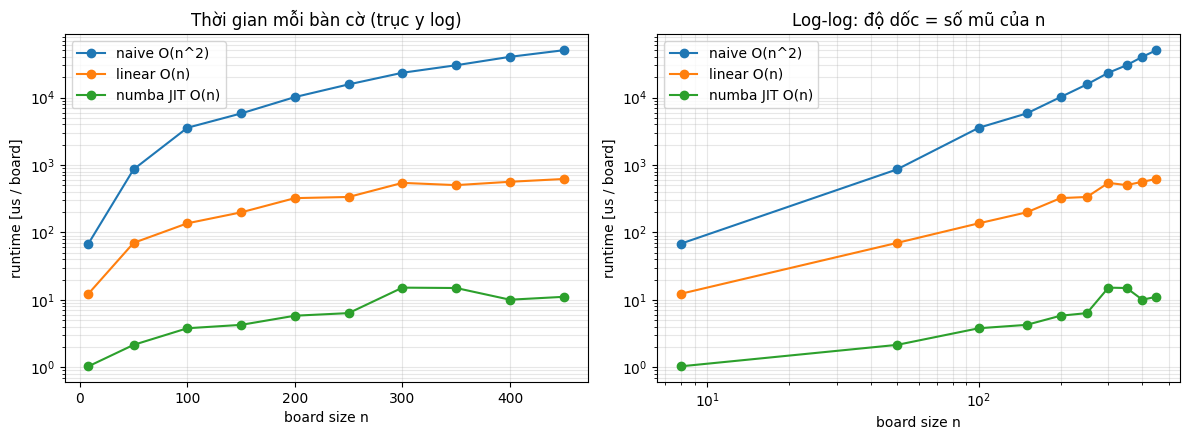

Độ dốc log-log ước lượng (n >= 50):
  naive O(n^2)    :  1.83
  linear O(n)     :  1.03
  numba JIT O(n)  :  0.86

Hệ số tăng tốc theo n:
    n  naive/linear  linear/jit  naive/jit
    8           5.5        11.9       66.0
   50          12.3        32.6      400.9
  100          26.1        36.0      940.7
  150          29.3        46.6     1366.6
  200          31.5        55.5     1748.9
  250          46.7        52.8     2467.7
  300          43.0        35.8     1538.7
  350          60.0        33.6     2015.2
  400          71.3        56.1     4002.9
  450          81.2        55.9     4545.0


In [11]:
# Đồ thị log-log và ước lượng độ dốc (số mũ của n) từ các cỡ bàn cờ n >= 50
x_arr = np.array(x)
mask = x_arr >= 50   # bỏ n = 8: ở cỡ nhỏ chi phí cố định (gọi hàm, tạo list) che mất xu hướng tiệm cận

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
series = {"naive O(n^2)": naive_times, "linear O(n)": linear_times, "numba JIT O(n)": jit_times}
for name, t in series.items():
    ax[0].plot(x_arr, t, marker="o", label=name)
    ax[1].loglog(x_arr, t, marker="o", label=name)
ax[0].set_yscale("log")
ax[0].set_title("Thời gian mỗi bàn cờ (trục y log)")
ax[1].set_title("Log-log: độ dốc = số mũ của n")
for a in ax:
    a.set_xlabel("board size n"); a.set_ylabel("runtime [us / board]"); a.legend(); a.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()

print("Độ dốc log-log ước lượng (n >= 50):")
for name, t in series.items():
    slope = np.polyfit(np.log(x_arr[mask]), np.log(np.array(t)[mask]), 1)[0]
    print(f"  {name:16s}: {slope:5.2f}")

print("\nHệ số tăng tốc theo n:")
print(f"{'n':>5} {'naive/linear':>13} {'linear/jit':>11} {'naive/jit':>10}")
for i, n in enumerate(x):
    print(f"{n:>5} {naive_times[i]/linear_times[i]:13.1f} {linear_times[i]/jit_times[i]:11.1f} {naive_times[i]/jit_times[i]:10.1f}")


## 2. Cách đọc kết quả

* **Độ dốc log-log** là số mũ thực nghiệm: nếu $T(n) \approx c\,n^{p}$ thì $\log T = p \log n + \log c$. Kỳ vọng: `naive` có $p \approx 2$, `linear` có $p \approx 1$. Với `jit`, $p$ có thể thấp hơn 1 ở cỡ nhỏ vì chi phí cố định mỗi lần gọi (chuyển mảng NumPy sang Numba, tạo danh sách) chiếm phần lớn thời gian; chỉ khi $n$ đủ lớn thì phần $O(n)$ mới trội lên.
* **Độ phức tạp thuật toán và lợi ích JIT là hai khái niệm khác nhau.** Đổi `naive` thành `linear` làm *đổi dạng đường cong* ($n^2 \to n$): lợi ích tăng theo $n$. Biên dịch JIT *không đổi dạng đường cong* mà chỉ giảm hệ số hằng $c$ (đường `jit` song song với `linear` trên đồ thị log-log), nên hệ số `linear/jit` xấp xỉ không đổi theo $n$.
* **Kết quả đã lưu trong notebook gốc** (bàn cờ $8 \times 8$): naive $\approx 26.1\,\mu s$, linear $\approx 5.6\,\mu s$, jit $\approx 0.56\,\mu s$, tức JIT nhanh hơn `linear` khoảng 10 lần và nhanh hơn `naive` khoảng 46 lần. Đây là số đo trên máy của người tạo notebook, bạn cần chạy lại để có số liệu của máy mình.

## 3. Vì sao phải gọi `conflicts_jit()` một lần trước khi đo?

Numba biên dịch hàm **ở lần gọi đầu tiên** (theo kiểu dữ liệu của đối số). Lần gọi đó bao gồm cả thời gian biên dịch (thường tính bằng trăm ms tới vài giây), lớn hơn thời gian chạy thực của hàm hàng nghìn lần. Nếu không loại trừ, thời gian trung bình sẽ bị phình lên và so sánh với `linear` sai lệch. Ô *khởi động* (warm-up) ở đầu phần so sánh thời gian chính là để việc biên dịch xảy ra ngoài vùng đo; ô đo riêng ở trên minh họa độ lớn của chi phí này.